# W12 : Time-Frequency and Multiscale Analysis

In [2]:
# !pip install PyWavelets

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal


def time_axis(fs, duration):
    # แกนเวลาแบบเดียวกับที่ใช้มาตั้งแต่สัปดาห์ที่ 1
    return np.arange(0, duration, 1/fs)

def generate_sine(f, t, A=1, p=0):
    y = A * np.sin(2 * np.pi * f * t + p)
    return y

def spectrum(x, fs, NFFT=-1):
    if NFFT == -1:
        NFFT = len(x)
    w = np.hanning(len(x))       # หน้าต่างยาวเท่าสัญญาณ  NFFT ที่ยาวกว่าคือการเติมศูนย์
    x_norm = (x - x.mean()) / x.std() *w
    X = np.fft.fft(x_norm, NFFT)
    X = X[:NFFT // 2]
    mag = np.abs(X) * 2 / len(x)
    freq = np.fft.rfftfreq(NFFT, 1/fs)[:len(mag)]   # แกนความถี่ชุดเดียวกับ signal.stft
    return freq, mag


## 1. Time-Frequency

FFT ของทั้งสัญญาณบอกว่า **มีความถี่อะไร** แต่ไม่บอกว่า **เกิดเมื่อไร**  สัญญาณที่กลับหลัง (A[::-1]) ได้ |FFT| เท่ากันทุกบิน
STFT : ตัดเป็น slice ยาว N -> คูณหน้าต่าง Hann -> FFT -> เลื่อนทีละ stride H -> เรียงเป็น array 2 มิติ (bin, slice)
spectrogram คือรูปของ |STFT| ในหน่วย dB  แกน x คือ เวลา  แกน y คือ ความถี่  สี คือ ความแรง
ใช้ signal.stft เป็นเครื่องมือ : representation (รูปร่างของ Z) และการอ่านผล (interpretation) ว่าความถี่ไหนเกิดตอนไหน

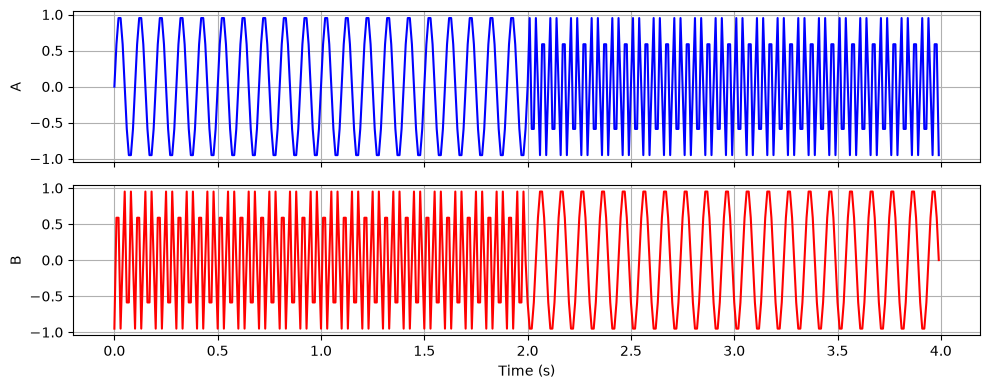

In [4]:
# Example 1.1 : สัญญาณ A (10 Hz แล้ว 30 Hz) และ B = A กลับหลัง (30 Hz แล้ว 10 Hz)  fs = 100, ยาว 4 วินาที
fs = 100
t_half = time_axis(fs, 2.0)
A = np.concatenate([generate_sine(10, t_half), generate_sine(30, t_half)])
B = A[::-1]
t = np.arange(len(A)) / fs

fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(t, A, 'b'); ax[0].set_ylabel('A'); ax[0].grid()
ax[1].plot(t, B, 'r'); ax[1].set_ylabel('B'); ax[1].grid()
ax[1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()


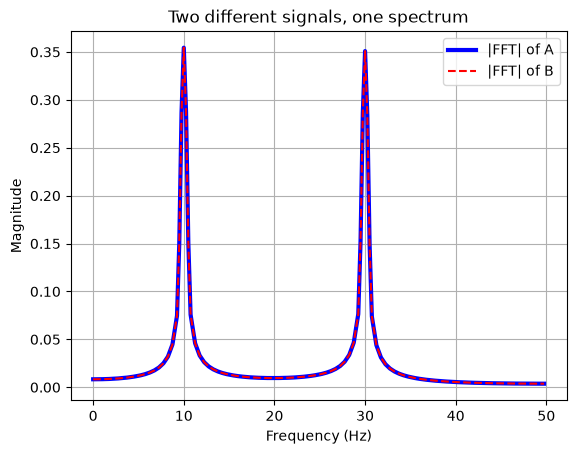

In [5]:
# Example 1.2 : FFT ของ A และ B ทับกัน
freq, mag_A = spectrum(A, fs)
freq, mag_B = spectrum(B, fs)
FFT_DIFF = np.abs(mag_A - mag_B).max()

plt.plot(freq, mag_A, 'b', lw=3, label='|FFT| of A')
plt.plot(freq, mag_B, 'r--', lw=1.5, label='|FFT| of B')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude'); plt.legend(); plt.grid()
plt.title('Two different signals, one spectrum')
plt.show()


f : (26,)   t : (15,)   Z : (26, 15)


C:\Users\HP\AppData\Local\Temp\ipykernel_9704\4144953611.py:9: RuntimeWarning: divide by zero encountered in log10
  Z_b_dB = 20*np.log10(np.abs(Z_b))


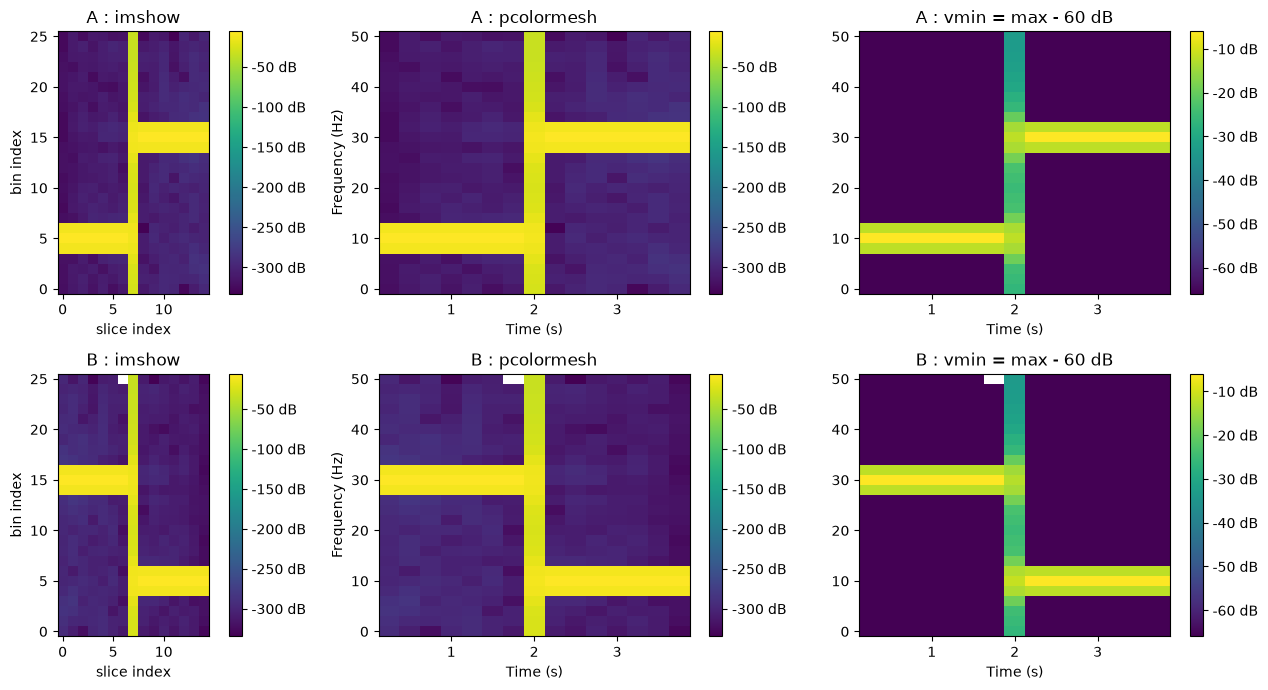

In [8]:
# Example 1.3 : signal.stft ของสัญญาณ A และ B จาก Example 1.1  (FFT แยกไม่ได้ แต่ STFT แยกได้)
L = int(0.5*fs)  # window length 0.5 s
H = int(0.25*fs) # hop 0.25 s
f_a, t_a, Z_a = signal.stft(A, fs, window='hann', nperseg=L, noverlap=L-H, boundary=None, padded=False)
f_b, t_b, Z_b = signal.stft(B, fs, window='hann', nperseg=L, noverlap=L-H, boundary=None, padded=False)
print('f :', f_a.shape, '  t :', t_a.shape, '  Z :', Z_a.shape)

Z_a_dB = 20*np.log10(np.abs(Z_a)) #change mag to db
Z_b_dB = 20*np.log10(np.abs(Z_b))
# Z_a_dB = np.abs(Z_a) #change mag to db
# Z_b_dB = np.abs(Z_b)
Z_list = [Z_a_dB, Z_b_dB]
names = ['A', 'B']

plt.figure(figsize=(14, 7))
for i in range(2):
    plt.subplot(2, 3, 3*i + 1)
    plt.imshow(Z_list[i], origin="lower")
    plt.colorbar(format="%+2.0f dB")
    plt.title(names[i] + ' : imshow'); plt.xlabel('slice index'); plt.ylabel('bin index')

    plt.subplot(2, 3, 3*i + 2)
    plt.pcolormesh(t_a, f_a, Z_list[i])
    plt.colorbar(format="%+2.0f dB")
    plt.title(names[i] + ' : pcolormesh'); plt.xlabel('Time (s)'); plt.ylabel('Frequency (Hz)')

    plt.subplot(2, 3, 3*i + 3)
    plt.pcolormesh(t_a, f_a, Z_list[i], vmin=Z_list[i].max() - 60)
    plt.colorbar(format="%+2.0f dB")
    plt.title(names[i] + ' : vmin = max - 60 dB'); plt.xlabel('Time (s)')

plt.tight_layout()
plt.show()


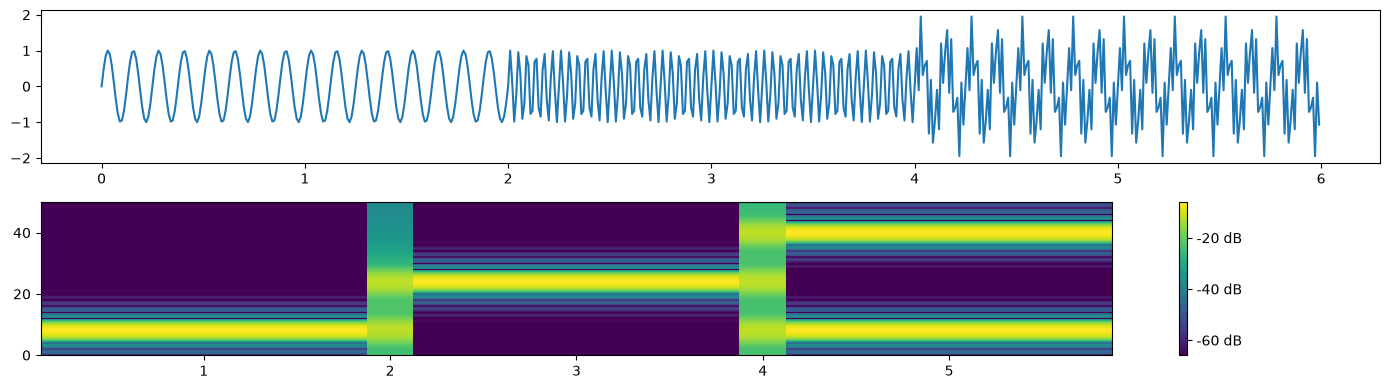

In [28]:
# Example 1.4 : สร้างฟังก์ชัน spectrogram_db 
# สัญญาณหลายความถี่ fs = 100 ยาว 6 วินาที
# 0-2 s : 8 Hz   2-4 s : 24 Hz   4-6 s : 8 Hz กับ 40 Hz พร้อมกัน
def spectrogram_db(x, fs, L, H, NFFT = -1):
    if NFFT == -1:
        NFFT = len(x)
    f, t, Z = signal.stft(x, fs, window='hann', nperseg=L, noverlap=L-H, boundary=None, padded=False, nfft = NFFT)
    return f, t, 20*np.log10(np.abs(Z))

fs = 100
t_part = time_axis(fs, 2.0)
part1 = generate_sine(8, t_part)
part2 = generate_sine(24, t_part)
part3 = generate_sine(8, t_part) + generate_sine(40, t_part)
x = np.concatenate([part1, part2, part3])
t = time_axis(fs, 6.0)

plt.figure( figsize=(14, 4))
plt.subplot(2,1,1)
plt.plot(t, x)

L, H = 50, 25          # window length 0.5 s   hop 0.25 s
S_f, S_t, S_db = spectrogram_db(x, fs, L, H)

plt.subplot(2,1,2)
plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60)
plt.colorbar(format="%+2.0f dB")

plt.tight_layout()
plt.show()


In [ ]:
# Exercise 1.1 : STFT ของสัญญาณหลายความถี่  fs = 100  แต่ละช่วงยาว 2 วินาที
# 0-2 s : 6 Hz    2-4 s : 16 Hz    4-6 s : 6 Hz กับ 30 Hz พร้อมกัน
# 1. สร้างสัญญาณ x11 ด้วย generate_sine แล้วต่อกันทั้ง 3 ช่วง
# 2. signal.stft ของ x11  window length L = 50 (0.5 s)  hop H = 25 (0.25 s)
# 3. print รูปร่างของ f, t, Z
# 4. วาด subplot (2,1,x) | สัญญาณ | spectrogram (dB) |
# 5. แต่ละช่วงเวลามีความถี่อะไร  เขียนลงใบงาน
fs = 100
L, H = 50, 25
# your code


In [10]:
# ตัวช่วยโหลดไฟล์และจัดเวลา (time alignment) แบบสัปดาห์ที่ 11
# เวลาในไฟล์มีแค่ ชั่วโมง นาที วินาที : กล้อง 25 ค่าต่อวินาที  PPG 100 ค่าต่อวินาที
def seconds(df):
    # ชั่วโมง นาที วินาที -> วินาที
    return (df["H"]*3600 + df["M"]*60 + df["S"]).to_numpy(float)

def spread(sec, fs):
    # ค่าที่อยู่ในวินาทีเดียวกัน -> กระจายให้ห่างเท่า ๆ กัน (add_ms ของสัปดาห์ที่ 11)
    t = sec.copy()
    starts = np.flatnonzero(np.r_[True, np.diff(sec) != 0])     # ค่าแรกของแต่ละวินาที
    ends = np.r_[starts[1:], len(sec)]
    for j in range(len(starts)):
        a, b = starts[j], ends[j]
        n = b - a
        k = np.arange(n)
        if j == 0 and n < fs:                     # วินาทีแรกไม่เต็ม : ชิดท้ายวินาที
            t[a:b] += (fs - n + k) / fs
        elif j == len(starts) - 1 and n < fs:     # วินาทีสุดท้ายไม่เต็ม : ชิดต้นวินาที
            t[a:b] += k / fs
        else:                                     # วินาทีเต็ม : กระจายเท่า ๆ กัน
            t[a:b] += k / n
    return t

def load_aligned(rgb_file, ppg_file, fs=100):
    # โหลด 2 ไฟล์ -> แกนเวลาร่วม fs Hz ในช่วงที่ซ้อนกัน -> interpolate ทุกช่อง
    rgb = pd.read_csv(rgb_file)
    ppg = pd.read_csv(ppg_file, sep=r"\s+", header=None, names=["H", "M", "S", "PPG"])
    t_rgb = spread(seconds(rgb), 25)
    t_ppg = spread(seconds(ppg), 100)
    t0 = max(t_rgb[0], t_ppg[0])
    t1 = min(t_rgb[-1], t_ppg[-1])
    t = t0 + np.arange(int(round((t1 - t0) * fs)) + 1) / fs
    r = np.interp(t, t_rgb, rgb["R"])
    g = np.interp(t, t_rgb, rgb["G"])
    b = np.interp(t, t_rgb, rgb["B"])
    p = np.interp(t, t_ppg, ppg["PPG"])
    return t - t0, np.vstack([r, g, b]), p

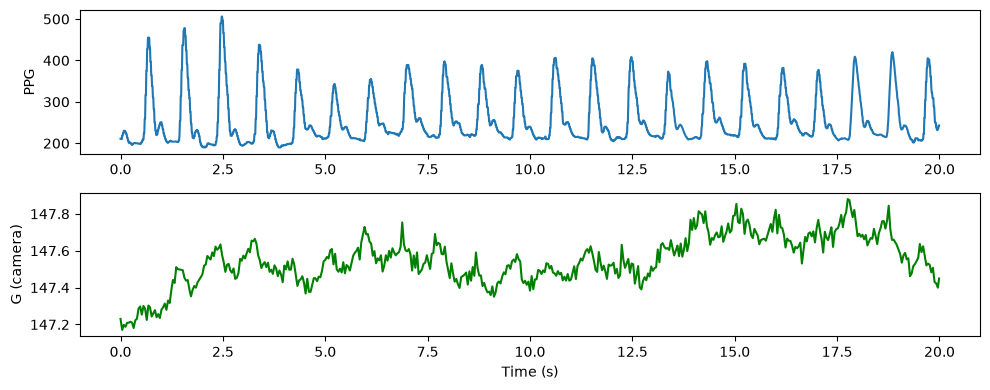

In [18]:
# เตรียมข้อมูลสำหรับ Exercise 1.2 และ section 3 : กล้องกับ PPG ของสัปดาห์ที่ 11
FS_TARGET = 100
T_PPG, iPPG, PPG = load_aligned("rgb_average_25fps.csv", "pulse_fs100Hz.txt", FS_TARGET)
G = iPPG[1] 

first20 = T_PPG < 20
plt.figure( figsize = (10, 4))
plt.subplot(2, 1, 1)
plt.plot(T_PPG[first20], PPG[first20]); plt.ylabel('PPG')
plt.subplot(2, 1, 2)
plt.plot(T_PPG[first20], G[first20], 'g'); plt.ylabel('G (camera)')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()


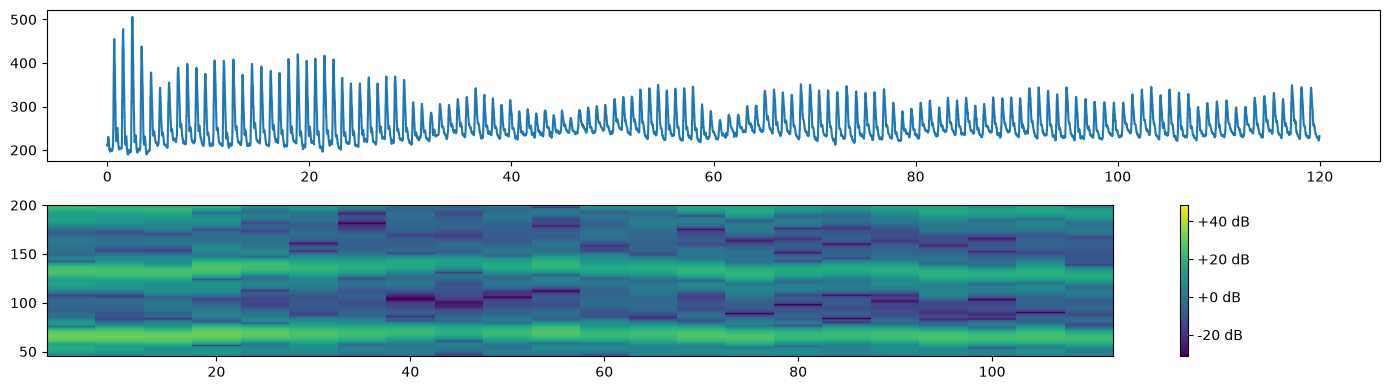

In [29]:
# Exercise 1.2 : STFT ของ PPG  window length 20 s  hop 10 s
# 1. preprocess สัญญาณ PPG ก่อน เช่น detrend, normalize, moving avg, sg-filter, filtering 0.7 ถึง 3 Hz
# 2. signal.stft ของ ppg ที่กรองแล้ว
# 3. วาด spectrogram (dB)
# 4. หายอด peak วิธีเดียวกับ fft (argmax) และทำเครื่องหมายบนกราฟ
# 5. print HR ในแต่ละหน้าต่าง

L_hr, H_hr = 10 * FS_TARGET, 5 * FS_TARGET       # window length 20 s   hop 10 s

# your code
PPG_window = PPG[:L_hr]
T_PPG_window = T_PPG[:L_hr]

plt.figure( figsize=(14, 4))
plt.subplot(2,1,1)
plt.plot(T_PPG, PPG)


S_f, S_t, S_db = spectrogram_db(PPG, FS_TARGET, L_hr, H_hr, len(PPG)*8)

plt.subplot(2,1,2)
plt.pcolormesh(S_t, S_f*60, S_db, vmin=S_db.max() - 80) # change to bpm : S_f*60
plt.colorbar(format="%+2.0f dB")
plt.ylim(45, 200)

plt.tight_layout()
plt.show()

## 2. Resolution

window length (L) : ยาว -> เส้นความถี่คม แต่เวลาเบลอ   สั้น -> เวลาคม แต่เส้นความถี่หนา  เลือกจากคำถามที่อยากตอบ
ระยะห่าง bin = fs / L   nfft (เติมศูนย์) ทำให้จุดถี่ขึ้น แต่แยก 2 ความถี่ที่ใกล้กันไม่ได้  ต้องเพิ่ม L
hop (H) กำหนดจำนวนหน้าต่าง ไม่ได้เปลี่ยนความคม

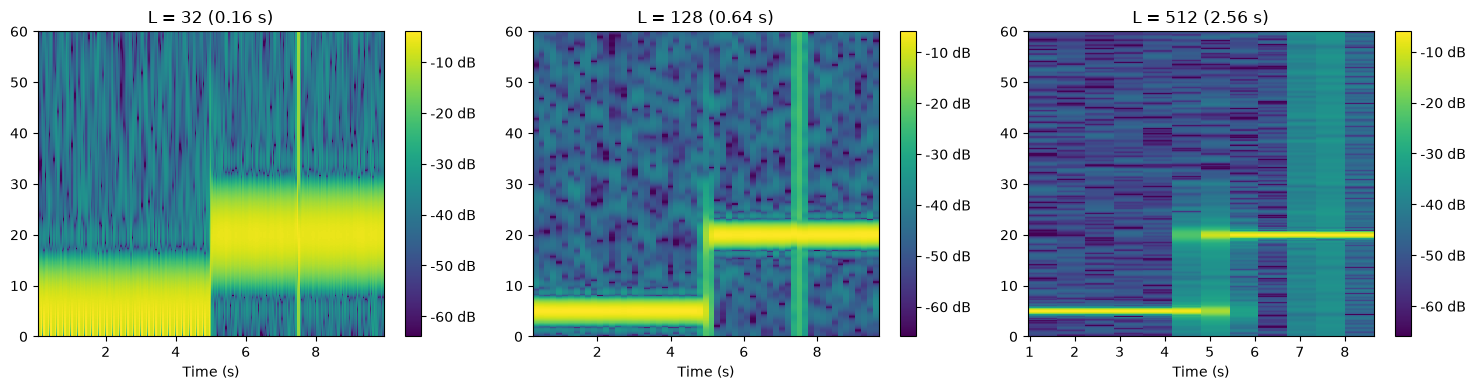

In [30]:
# Example 2.1 : สัญญาณทดสอบ 5 Hz (0-5 s) -> 20 Hz (5-10 s)  click 1 ตัวอย่างที่ 7.5 s  fs = 200
# window length L = 32, 128, 512  (hop H = L / 4)
FS_X = 200
CLICK_S = 7.5
t_x = np.arange(10 * FS_X) / FS_X
x_test = np.where(t_x < 5, generate_sine(5, t_x), generate_sine(20, t_x))
x_test[int(CLICK_S * FS_X)] += 4                     # click ยาวแค่ 1 ตัวอย่าง
x_test = x_test + 0.05 * np.random.default_rng(12).standard_normal(len(x_test))

L_list = [32, 128, 512]
plt.figure(figsize=(15, 4))
for i in range(3):
    L = L_list[i]
    S_f, S_t, S_db = spectrogram_db(x_test, FS_X, L, L // 4, len(x_test))
    plt.subplot(1, 3, i + 1)
    plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60)
    plt.colorbar(format="%+2.0f dB")
    plt.ylim(0, 60); plt.title(f'L = {L} ({L / FS_X} s)'); plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()


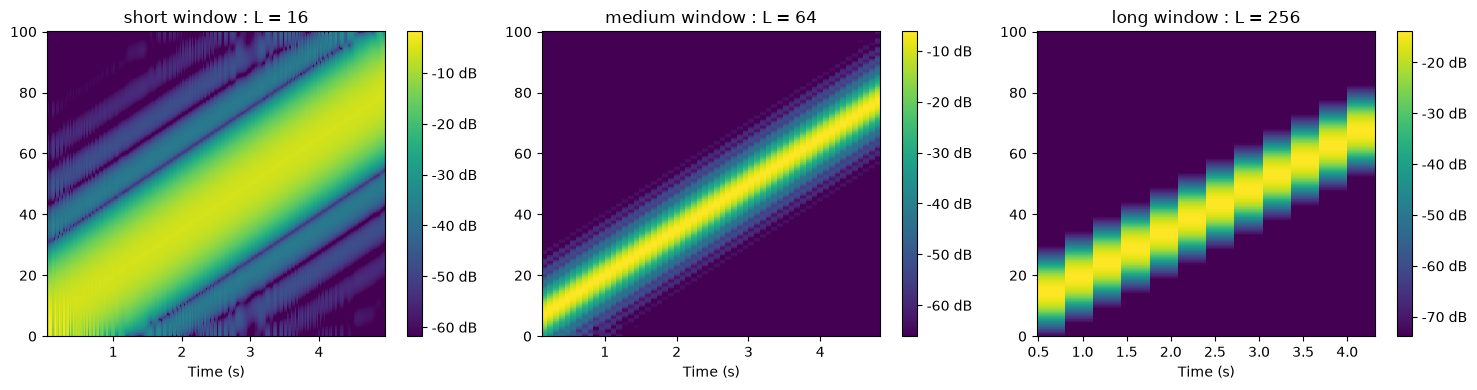

In [31]:
# Example 2.2 : spectrogram ขึ้นกับ window  chirp (ความถี่เพิ่มจาก 5 เป็น 80 Hz ใน 5 วินาที)  fs = 200
# window สั้น : เวลาเด่น   กลาง : สมดุล   ยาว : ความถี่เด่น
t_c = np.arange(5 * FS_X) / FS_X
x_chirp = signal.chirp(t_c, f0=5, t1=5, f1=80)
L_list = [16, 64, 256]
names = ['short', 'medium', 'long']

plt.figure(figsize=(15, 4))
for i in range(3):
    S_f, S_t, S_db = spectrogram_db(x_chirp, FS_X, L_list[i], L_list[i] // 4)
    plt.subplot(1, 3, i + 1)
    plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60)
    plt.colorbar(format="%+2.0f dB")
    plt.title(f'{names[i]} window : L = {L_list[i]}'); plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()


In [32]:
# Example 2.3 : ระยะห่าง bin = fs / L  (L = window length)  หน้าต่างยิ่งยาว ยิ่งละเอียด
fs = 100
for L in [20, 100]:
    T_window = L / fs                       # ความยาวหน้าต่าง (วินาที)
    df = fs / L                             # ระยะห่างระหว่าง bin (Hz)
    print('L =', L, ': หน้าต่างยาว', T_window, 's   ระยะห่าง bin =', df, 'Hz')
    print('        bin แรก ๆ :', np.fft.rfftfreq(L, 1/fs)[:6], 'Hz')


L = 20 : หน้าต่างยาว 0.2 s   ระยะห่าง bin = 5.0 Hz
        bin แรก ๆ : [ 0.  5. 10. 15. 20. 25.] Hz
L = 100 : หน้าต่างยาว 1.0 s   ระยะห่าง bin = 1.0 Hz
        bin แรก ๆ : [0. 1. 2. 3. 4. 5.] Hz


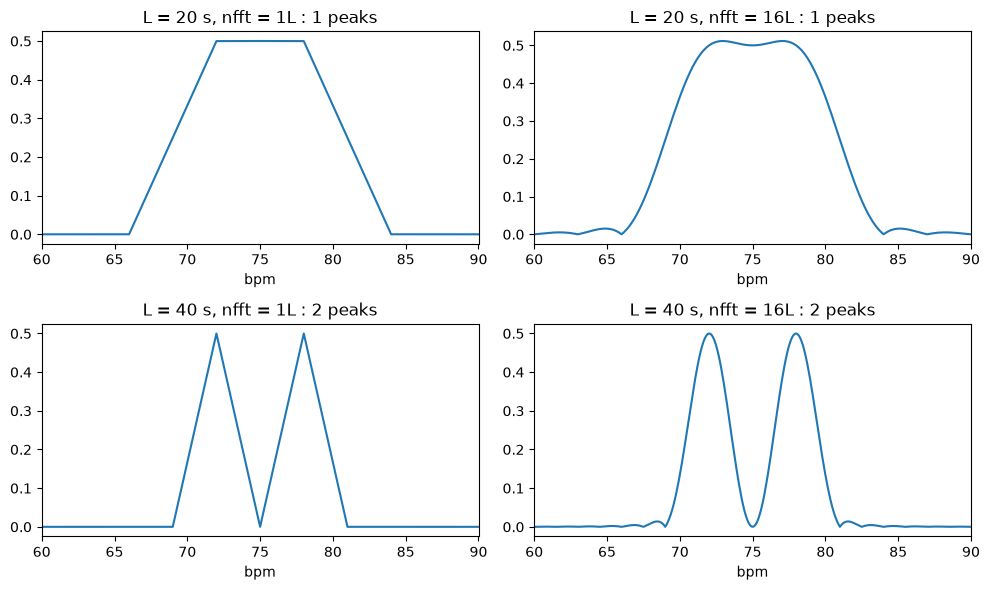

In [33]:
# Example 2.4 : resolution มี 2 ความหมาย  ชีพจร 2 ค่าปนกัน 72 bpm (1.2 Hz) กับ 78 bpm (1.3 Hz)  fs = 100
# เพิ่ม nfft (เติมศูนย์)  กับ  เพิ่ม window length (L)  แบบไหนแยก 2 ยอดได้
FS_HR = 100

def two_pulses(length_s):
    t = np.arange(length_s * FS_HR) / FS_HR
    return generate_sine(1.2, t) + generate_sine(1.3, t)

def count_peaks(freq, mag):
    # จำนวนยอดในย่าน 0.9 ถึง 1.6 Hz ที่สูงอย่างน้อย 5 % ของยอดใหญ่สุด
    band = (freq >= 0.9) & (freq <= 1.6)
    peaks, _ = signal.find_peaks(mag[band], prominence=0.05 * mag[band].max())
    return len(peaks)

plt.figure(figsize=(10, 6))
k_plot = 1
for length_s in [20, 40]:
    x = two_pulses(length_s)
    for k in [1, 16]:
        freq, mag = spectrum(x, FS_HR, k * len(x))      # nfft = k x L
        n_peaks = count_peaks(freq, mag)
        plt.subplot(2, 2, k_plot)
        plt.plot(freq * 60, mag)
        plt.xlim(60, 90); plt.xlabel('bpm')
        plt.title(f'L = {length_s} s, nfft = {k}L : {n_peaks} peaks')
        k_plot = k_plot + 1
plt.tight_layout()
plt.show()


H = 128 : จำนวนหน้าต่าง = 15
H = 64 : จำนวนหน้าต่าง = 30
H = 16 : จำนวนหน้าต่าง = 118


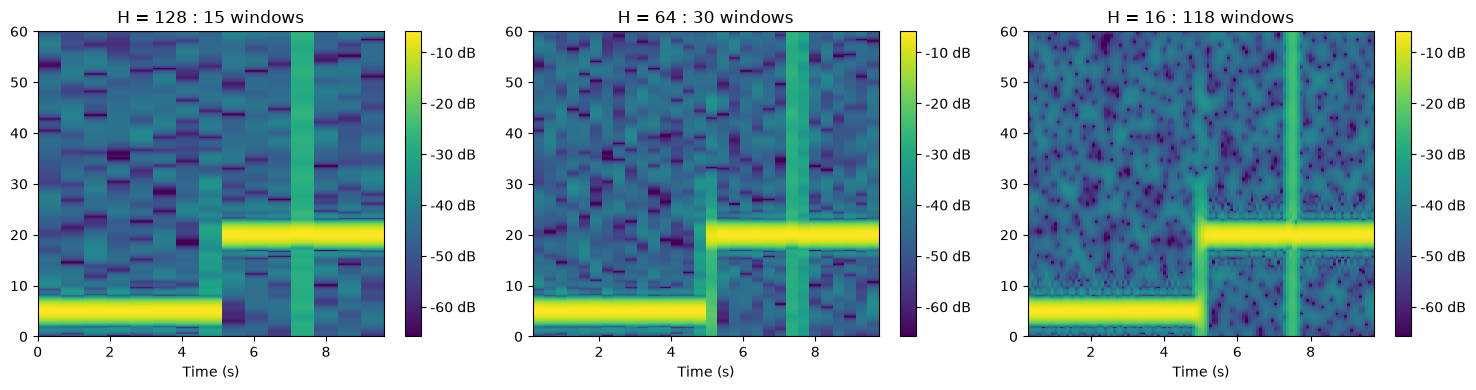

In [35]:
# Example 2.5 : window length เท่าเดิม L = 128  เปลี่ยนแค่ hop H = 128, 64, 16
H_list = [128, 64, 16]
plt.figure(figsize=(15, 4))
for i in range(3):
    S_f, S_t, S_db = spectrogram_db(x_test, FS_X, 128, H_list[i], len(x_test))
    print('H =', H_list[i], ': จำนวนหน้าต่าง =', len(S_t))
    plt.subplot(1, 3, i + 1)
    plt.pcolormesh(S_t, S_f, S_db, vmin=S_db.max() - 60)
    plt.colorbar(format="%+2.0f dB")
    plt.ylim(0, 60); plt.title(f'H = {H_list[i]} : {len(S_t)} windows'); plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_9704\2540701326.py:8: RuntimeWarning: divide by zero encountered in log10
  return f, t, 20*np.log10(np.abs(Z))


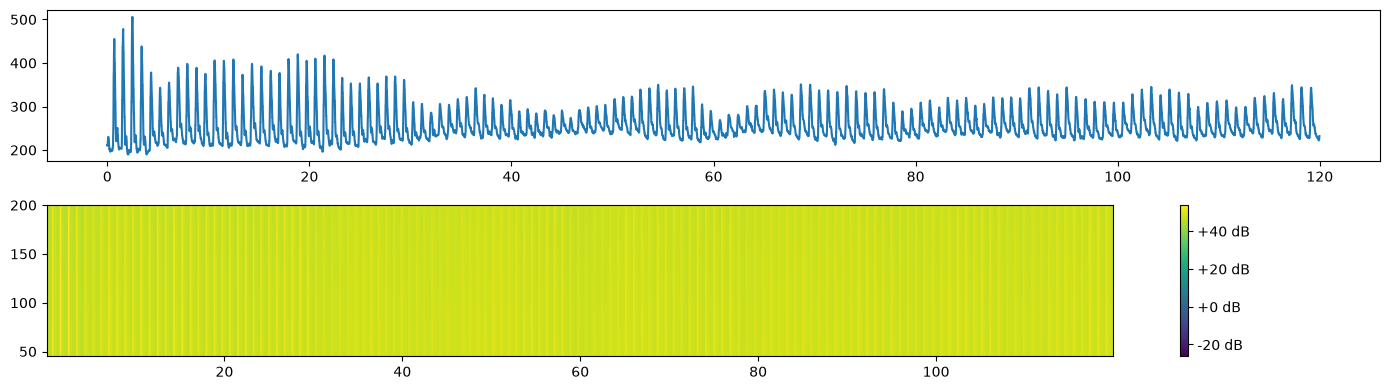

In [37]:
# Exercise 2.1 : ทดลอง window length กับสัญญาณ x11 จาก Exercise 1.1
# 1. STFT ของ x11 ด้วย L = 16, 50, 200 (0.16, 0.5, 2 วินาที)  และ H = L / 4
# 2. วาด spectrogram (dB) ทั้ง 3 แบบด้วย subplot (1,3,x)
# 3. ทำตาราง : L | ระยะห่าง bin (Hz) | จำนวนหน้าต่าง
# 4. L ไหนแยก 6 Hz กับ 30 Hz ในช่วงสุดท้ายได้ชัด  L ไหนเห็นเวลาที่ความถี่เปลี่ยนได้คม  เขียนลงใบงาน
# ส่งรูปในไดร์ฟ
L_list = [16, 50, 200]
# your code
L_hr = 10
H_hr = int(0.5*L_hr)       # window length 20 s   hop 10 s

# your code
PPG_window = PPG[:L_hr]
T_PPG_window = T_PPG[:L_hr]

plt.figure( figsize=(14, 4))
plt.subplot(2,1,1)
plt.plot(T_PPG, PPG)


S_f, S_t, S_db = spectrogram_db(PPG, FS_TARGET, L_hr, H_hr, len(PPG)*8)

plt.subplot(2,1,2)
plt.pcolormesh(S_t, S_f*60, S_db, vmin=S_db.max() - 80) # change to bpm : S_f*60
plt.colorbar(format="%+2.0f dB")
plt.ylim(45, 200)

plt.tight_layout()
plt.show()

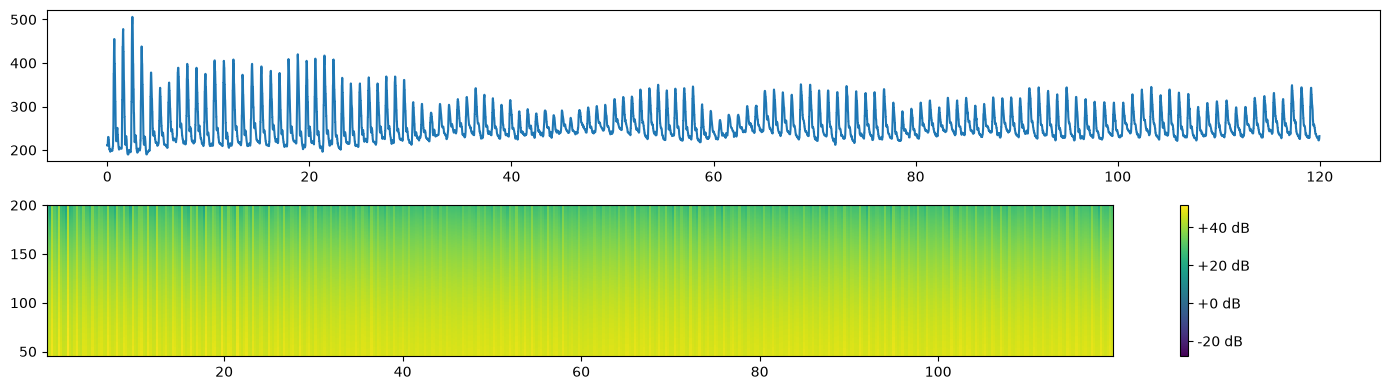

In [41]:
# Exercise 2.1 : ทดลอง window length กับสัญญาณ x11 จาก Exercise 1.1
# 1. STFT ของ x11 ด้วย L = 16, 50, 200 (0.16, 0.5, 2 วินาที)  และ H = L / 4
# 2. วาด spectrogram (dB) ทั้ง 3 แบบด้วย subplot (1,3,x)
# 3. ทำตาราง : L | ระยะห่าง bin (Hz) | จำนวนหน้าต่าง
# 4. L ไหนแยก 6 Hz กับ 30 Hz ในช่วงสุดท้ายได้ชัด  L ไหนเห็นเวลาที่ความถี่เปลี่ยนได้คม  เขียนลงใบงาน
# ส่งรูปในไดร์ฟ
L_list = [16, 50, 200]
# your code
L_hr = 50
H_hr = int(0.5*L_hr)       # window length 20 s   hop 10 s

# your code
PPG_window = PPG[:L_hr]
T_PPG_window = T_PPG[:L_hr]

plt.figure( figsize=(14, 4))
plt.subplot(2,1,1)
plt.plot(T_PPG, PPG)


S_f, S_t, S_db = spectrogram_db(PPG, FS_TARGET, L_hr, H_hr, len(PPG))

plt.subplot(2,1,2)
plt.pcolormesh(S_t, S_f*60, S_db, vmin=S_db.max() - 80) # change to bpm : S_f*60
plt.colorbar(format="%+2.0f dB")
plt.ylim(45, 200)

plt.tight_layout()
plt.show()

In [ ]:
# Exercise 2.2 : ทดลอง window length กับ PPG (ppg_f จาก Exercise 1.2)
# 1. STFT ของ ppg_f ด้วย L = 10, 20, 40 วินาที  และ H = L / 2
# 2. วาด spectrogram (dB) ทั้ง 3 แบบด้วย subplot (1,3,x)  แกนตั้งเป็น bpm  ทำเครื่องหมายยอดสูงสุด
# 3. ทำตาราง : L (s) | จำนวนหน้าต่าง | ระยะห่าง bin (bpm) | HR ต่ำสุด | HR สูงสุด
# เขียนตารางลงใบงาน และส่งรูปในไดร์ฟ
L_s = [10, 20, 40]
# your code


## 3. STFT on iPPG

iPPG คือชีพจรจากกล้อง : ช่อง R, G, B ของสัปดาห์ที่ 11  STFT ทั้งเส้นด้วย L = 20 s  H = 10 s แล้วคูณแกนความถี่ด้วย 60
ICA แยก R, G, B เป็น 3 IC แล้วเลือก IC ที่ยอดในย่านชีพจรเด่นที่สุด (แบบสัปดาห์ที่ 11)
ไฟล์ S2 ถึง S8 ใช้ทำงานคู่ (pair work) ใน Exercise 3.3

In [ ]:
# ตัวช่วยของ section 3 : กรอง (prep), ICA (run_ica, pick_ic), spectrogram ของย่านชีพจร (hr_spectrogram, plot_hr)
from sklearn.decomposition import FastICA

BAND = (0.7, 3.0)                                 # ย่านชีพจร 42 ถึง 180 bpm
L_HR, H_HR = 20 * FS_TARGET, 10 * FS_TARGET      # window length 20 s   hop 10 s

def prep(x):
    # detrend + normalize -> Savitzky-Golay -> band-pass 0.7 ถึง 3 Hz  (สัปดาห์ที่ 11)
    y = signal.detrend(x)
    y = (y - y.mean()) / y.std()
    y = signal.savgol_filter(y, 21, 2)
    b, a = signal.butter(2, BAND, fs=FS_TARGET, btype="bandpass")
    return signal.lfilter(b, a, y)

def run_ica(X):
    # X : แถวละ 1 ช่อง -> z-score -> FastICA -> แถวละ 1 IC
    Z = (X.T - X.mean(axis=1)) / X.std(axis=1)
    ica = FastICA(n_components=len(X), whiten="unit-variance", random_state=0, max_iter=2000, tol=1e-4)
    return ica.fit_transform(Z).T

def pick_ic(IC):
    # IC ที่ยอดในย่านชีพจรเด่นที่สุด (ไม่ต้องใช้ PPG)
    shares = []
    for ic in IC:
        freq, mag = spectrum(ic, FS_TARGET)
        P = mag[(freq >= BAND[0]) & (freq <= BAND[1])] ** 2
        shares.append(P.max() / P.sum())
    return int(np.argmax(shares))

def hr_spectrogram(y):
    # STFT -> เก็บเฉพาะย่านชีพจร -> bpm   hr = ยอดสูงสุดของแต่ละหน้าต่าง
    f, t, Z = signal.stft(y, FS_TARGET, window='hann', nperseg=L_HR, noverlap=L_HR-H_HR,
                          boundary=None, padded=False)
    band = (f >= BAND[0]) & (f <= BAND[1])
    mag = np.abs(Z[band])
    bpm = f[band] * 60
    return t, bpm, 20*np.log10(mag), bpm[np.argmax(mag, axis=0)]

def plot_hr(t, bpm, S_db, title):
    # วาด spectrogram ของย่านชีพจรลงใน subplot ปัจจุบัน
    plt.pcolormesh(t, bpm, S_db, vmin=S_db.max() - 40)
    plt.colorbar(format="%+2.0f dB")
    plt.title(title); plt.xlabel('Time (s)'); plt.ylabel('bpm'); plt.ylim(42, 150)


In [ ]:
# Example 3.1 : STFT ของ iPPG ช่อง R, G, B  (L = 20 s  H = 10 s)  เทียบชีพจรกับ PPG
t_ref, bpm, S_ref, hr_ref = hr_spectrogram(prep(PPG))        # ชีพจรจาก PPG (reference)
names = ['R', 'G', 'B']
hr_rgb = []

plt.figure(figsize=(15, 4))
for i in range(3):
    t_c, bpm, S_c, hr_c = hr_spectrogram(prep(iPPG[i]))
    hr_rgb.append(hr_c)
    plt.subplot(1, 3, i + 1)
    plot_hr(t_c, bpm, S_c, 'STFT ' + names[i])
    plt.plot(t_c, hr_c, 'wo', ms=8)
    plt.plot(t_ref, hr_ref, 'rx', ms=8, mew=2)
plt.tight_layout()
plt.show()

for i in range(3):
    print(names[i], ': HR =', hr_rgb[i], '  ตรงกับ PPG', (hr_rgb[i] == hr_ref).sum(), 'จาก', len(hr_ref))


In [ ]:
# Exercise 3.1 : ทดลอง resolution กับ iPPG ช่อง G  window length L = 20 วินาทีเท่าเดิม
# (ก) nfft = 4L (เติมศูนย์)    (ข) hop H = 2 วินาที   เทียบกับแบบเดิม (nfft = L, H = 10 s)
# 1. preprocess ช่อง G ด้วย prep
# 2. STFT ทั้ง 3 แบบ แล้วหายอดสูงสุดในย่าน 0.7 ถึง 3 Hz ของแต่ละหน้าต่าง
# 3. print ระยะห่างจุดบนแกนความถี่ (bpm), จำนวนหน้าต่าง และ HR แต่ละหน้าต่าง
# 4. อะไรเปลี่ยน อะไรไม่เปลี่ยน  เขียนลงใบงาน
L = 20 * FS_TARGET
settings = [('เดิม : nfft = L, H = 10 s', L, 10),
            ('(ก) nfft = 4L, H = 10 s', 4 * L, 10),
            ('(ข) nfft = L, H = 2 s', L, 2)]
# your code


In [ ]:
# Example 3.2 : ICA แยก R, G, B เป็น 3 IC (แบบสัปดาห์ที่ 11)  แล้วดูสเปกตรัมของแต่ละ IC
X_rgb = np.vstack([prep(iPPG[0]), prep(iPPG[1]), prep(iPPG[2])])
IC = run_ica(X_rgb)
k_pulse = pick_ic(IC)                            # IC ที่ยอดในย่านชีพจรเด่นที่สุด
ic_pulse = IC[k_pulse]

plt.figure(figsize=(15, 4))
for i in range(3):
    freq, mag = spectrum(IC[i], FS_TARGET)
    plt.subplot(1, 3, i + 1)
    plt.plot(freq * 60, mag)
    plt.xlim(0, 240); plt.xlabel('bpm')
    plt.title(f'IC{i + 1} : peak {freq[np.argmax(mag)] * 60:.1f} bpm')
plt.tight_layout()
plt.show()
print('IC ที่เป็นชีพจร = IC' + str(k_pulse + 1))


In [ ]:
# Exercise 3.2 : STFT ของ IC ที่เป็นชีพจร (ic_pulse จาก Example 3.2)  ทดลอง window length
# 1. STFT ของ ic_pulse ด้วย L = 10, 20, 40 วินาที  และ H = L / 2
# 2. วาด spectrogram (dB) ทั้ง 3 แบบด้วย subplot (1,3,x)  แกนตั้ง bpm  วางยอดสูงสุดเป็นวงกลมสีขาว
# 3. ทำตาราง : L (s) | จำนวนหน้าต่าง | ระยะห่าง bin (bpm) | HR ต่ำสุด | HR สูงสุด
# 4. L ไหนเหมาะกับการวัดชีพจรที่สุด เพราะอะไร  เขียนลงใบงาน
# ส่งรูปในไดร์ฟ
L_s = [10, 20, 40]
# your code


In [ ]:
# Exercise 3.3 : งานคู่ (pair work)  ไฟล์ของคู่ตัวเอง (เปลี่ยน SUBJECT เป็น S2 ถึง S8)
# 1. load_aligned ไฟล์ของคู่ตัวเอง แล้ว prep ทุกช่อง
# 2. ICA ด้วย run_ica แล้วเลือก IC ที่เป็นชีพจรด้วย pick_ic
# 3. hr_spectrogram ของ IC และของ PPG  (L = 20 s  H = 10 s)
# 4. วาด subplot (1,2,x) | IC + HR | PPG + HR |
# 5. print HR แต่ละหน้าต่างของ IC และ PPG, MAE และหน้าต่างที่ผิดตั้งแต่ 6 bpm ขึ้นไป  เขียนลงใบงาน
# ส่งรูปในไดร์ฟ
SUBJECT = "S3"
T_s, iPPG_s, PPG_s = load_aligned(SUBJECT + "_rgb_average.csv", SUBJECT + "_referencePulse.txt")
# your code


## 4. Multiscale

Haar ระดับ 1 : จับคู่ตัวที่ติดกัน  A = (x0 + x1) / 2 คือค่าเฉลี่ย  D = (x0 - x1) / 2 คือรายละเอียด  ย้อนกลับได้ครบ x0 = A + D, x1 = A - D
หารด้วย 2 พลังงานหายไปครึ่งหนึ่ง  หารด้วย √2 พลังงานเท่าเดิม  ไลบรารี pywt ใช้แบบ √2
DWT หลายระดับ = ทำ Haar ซ้ำบน A : D1 เร็วที่สุด  D2 ช้าลง ...  A แนวโน้ม  (pywt.wavedec / pywt.waverec)

In [55]:
# Exercise 4.1 : Haar หารด้วย 2 ด้วยมือ (ทำในใบงาน) แล้วตรวจด้วยโค้ด
# x = [4, 6, 10, 12, 8, 2, 5, 5]
# 1. ระดับ 1 : A1 = (x0 + x1) / 2   D1 = (x0 - x1) / 2  ของทุกคู่
# 2. ระดับ 2 : ทำซ้ำกับ A1 ได้ A2, D2
# 3. ย้อนกลับจาก A2, D2, D1 ให้ได้ x เดิม (x0 = A + D,  x1 = A - D)
x41 = np.array([4, 6, 10, 12, 8, 2, 5, 5], dtype=float)
# your code
# A1 and D1 level 1
print("level 1")
A1 = (x41[::2] + x41[1::2]) / 2
print(A1)
D1 = (x41[::2] - x41[1::2]) / 2
print(D1)

# print(A1 + D1); print(A1 - D1)
# level 2
print("level 2")
A2 = (A1[::2] + A1[1::2]) / 2
D2 = (A1[::2] - A1[1::2]) / 2
print(A2)
print(D2)

#level 3
print("level 3")
A3 = (A2[::2] + A2[1::2]) / 2
D3 = (A2[::2] - A2[1::2]) / 2
print(A3)
print(D3)

level 1
[ 5. 11.  5.  5.]
[-1. -1.  3.  0.]
level 2
[8. 5.]
[-3.  0.]
level 3
[6.5]
[1.5]


In [56]:
# Example 4.1 : Haar หารด้วย 2 (ค่าเฉลี่ย) และการย้อนกลับ  ตรวจคำตอบ Exercise 4.1
def haar_level_divide2(x):
    A = (x[::2] + x[1::2]) / 2
    D = (x[::2] - x[1::2]) / 2
    return A, D

def inverse_divide2(A, D):
    # x0 = A + D  และ  x1 = A - D  แล้วเรียงสลับกลับเป็นเส้นเดียว
    x = np.zeros(2 * len(A))
    x[::2] = A + D
    x[1::2] = A - D
    return x

A1, D1 = haar_level_divide2(x41)          # ระดับ 1
A2, D2 = haar_level_divide2(A1)           # ระดับ 2
print('A1 =', A1, '  D1 =', D1)
print('A2 =', A2, '  D2 =', D2)

# ย้อนกลับ : A2, D2 -> A1  แล้ว  A1, D1 -> x
A1_rec = inverse_divide2(A2, D2)
x_rec = inverse_divide2(A1_rec, D1)
print('ย้อนกลับ =', x_rec, '  ตรงกับ x ?', np.allclose(x_rec, x41))


A1 = [ 5. 11.  5.  5.]   D1 = [-1. -1.  3.  0.]
A2 = [8. 5.]   D2 = [-3.  0.]
ย้อนกลับ = [ 4.  6. 10. 12.  8.  2.  5.  5.]   ตรงกับ x ? True


พลังงานของ x               = 236.0
หารด้วย 2       : A + D    = 118.0
หารด้วย sqrt(2) : A + D    = 236.0


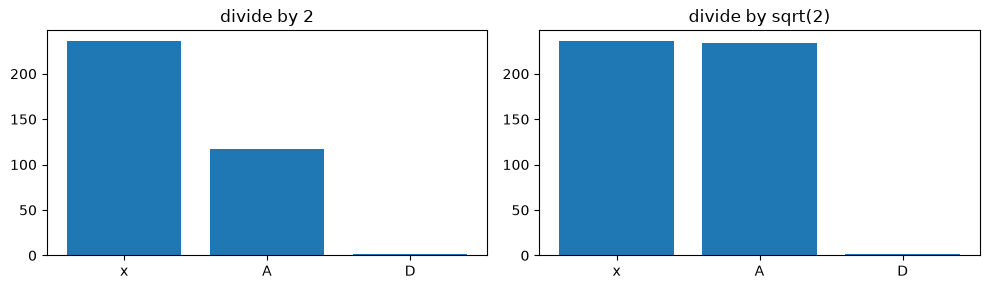

In [57]:
# Example 4.2 : พลังงานของ Haar ระดับ 1  หารด้วย 2 เทียบกับหารด้วย sqrt(2)
x = np.array([8, 10, 6, 6], dtype=float)

def energy(x):
    return np.sum(x**2)

def haar_level(x):
    A = (x[::2] + x[1::2]) / np.sqrt(2)
    D = (x[::2] - x[1::2]) / np.sqrt(2)
    return A, D

A_2, D_2 = haar_level_divide2(x)          # หารด้วย 2
A_r, D_r = haar_level(x)                  # หารด้วย sqrt(2)
print('พลังงานของ x               =', energy(x))
print('หารด้วย 2       : A + D    =', energy(A_2) + energy(D_2))
print('หารด้วย sqrt(2) : A + D    =', energy(A_r) + energy(D_r))

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.bar(['x', 'A', 'D'], [energy(x), energy(A_2), energy(D_2)]); plt.title('divide by 2')
plt.subplot(1, 2, 2)
plt.bar(['x', 'A', 'D'], [energy(x), energy(A_r), energy(D_r)]); plt.title('divide by sqrt(2)')
plt.tight_layout()
plt.show()


In [58]:
# Exercise 4.2 : พลังงานของ x จาก Exercise 4.1 (ทำในใบงาน) แล้วตรวจด้วยโค้ด
# 1. พลังงานของ x = ผลรวมของค่ายกกำลังสอง
# 2. Haar ระดับ 1 หารด้วย 2 : พลังงานของ A1 + D1
# 3. Haar ระดับ 1 หารด้วย sqrt(2) : พลังงานของ A1 + D1
# 4. แบบไหนพลังงานเท่าเดิม  เขียนลงใบงาน
# your code


ความยาว A : 400   cA : 200   cD : 200
pywt ตรงกับ haar_level ? True
พลังงาน A = 200.0   cA + cD = 200.0


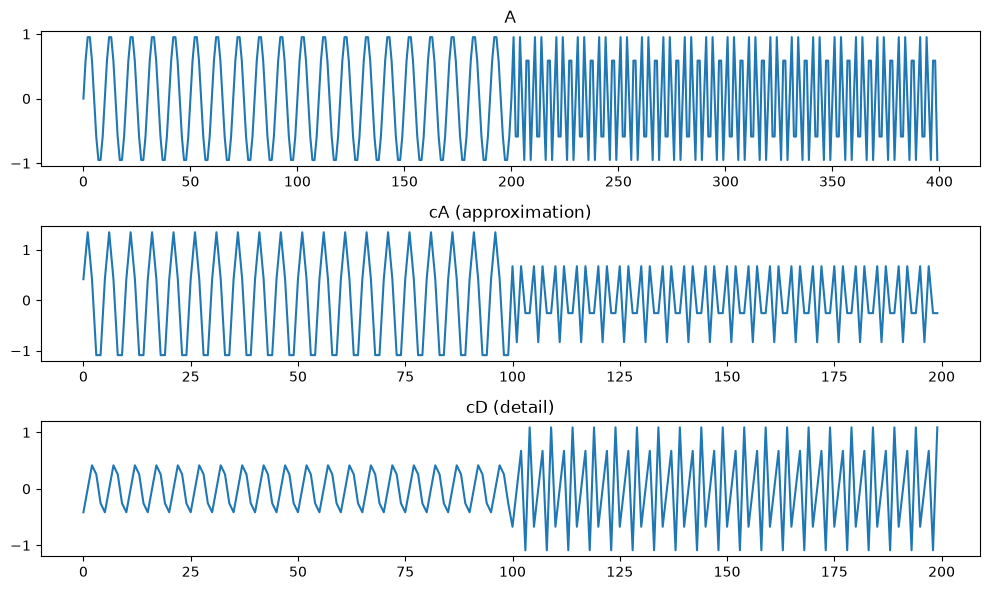

In [59]:
# Example 4.3 : pywt.dwt(x, 'haar') กับสัญญาณ A จาก Example 1.1  (pywt หารด้วย sqrt(2))
import pywt

cA, cD = pywt.dwt(A, 'haar')
A_r, D_r = haar_level(A)
print('ความยาว A :', len(A), '  cA :', len(cA), '  cD :', len(cD))
print('pywt ตรงกับ haar_level ?', np.allclose(cA, A_r) and np.allclose(cD, D_r))
print('พลังงาน A =', round(energy(A), 6), '  cA + cD =', round(energy(cA) + energy(cD), 6))

plt.figure(figsize=(10, 6))
plt.subplot(3, 1, 1); plt.plot(A); plt.title('A')
plt.subplot(3, 1, 2); plt.plot(cA); plt.title('cA (approximation)')
plt.subplot(3, 1, 3); plt.plot(cD); plt.title('cD (detail)')
plt.tight_layout()
plt.show()


A3 : ยาว 50
D3 : ยาว 50
D2 : ยาว 100
D1 : ยาว 200
ย้อนกลับ ต่างจากเดิมมากสุด = 5.551115123125783e-16


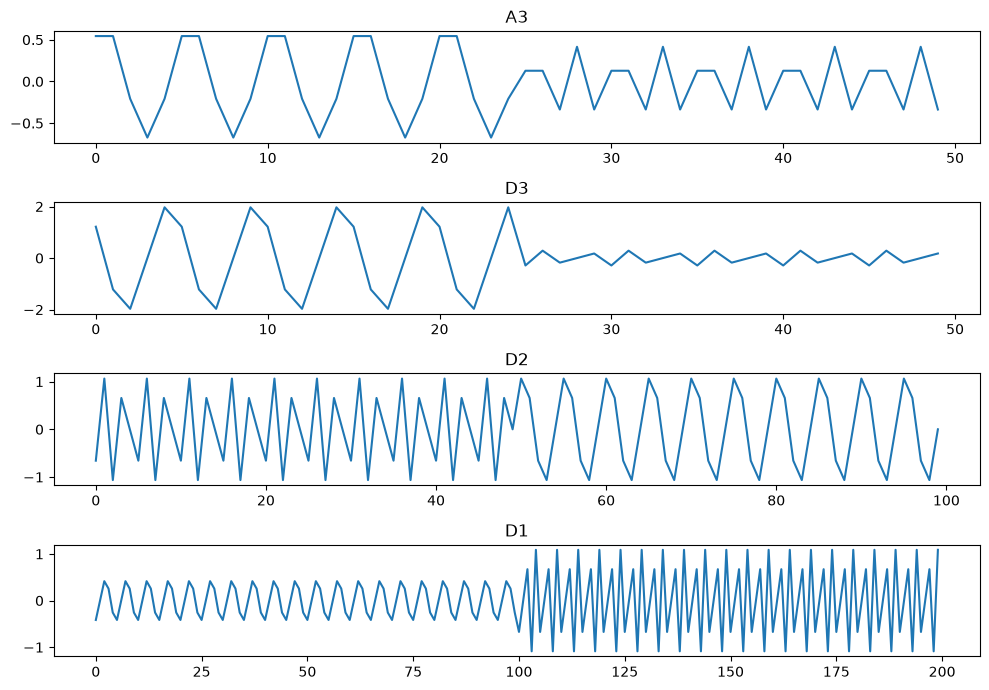

In [60]:
# Example 4.4 : DWT หลายระดับ pywt.wavedec  แล้วย้อนกลับด้วย pywt.waverec  (สัญญาณ A จาก Example 4.3)
coeffs = pywt.wavedec(A, 'haar', level=3)        # [A3, D3, D2, D1]
names = ['A3', 'D3', 'D2', 'D1']
for i in range(4):
    print(names[i], ': ยาว', len(coeffs[i]))
# rec-reconstruct, dec-deconstruct
A_rec = pywt.waverec(coeffs, 'haar')
print('ย้อนกลับ ต่างจากเดิมมากสุด =', np.abs(A_rec - A).max())

plt.figure(figsize=(10, 7))
for i in range(4):
    plt.subplot(4, 1, i + 1)
    plt.plot(coeffs[i]); plt.title(names[i])
plt.tight_layout()
plt.show()


In [ ]:
# Example 4.5 : DWT ของ iPPG (ช่อง G)  fs = 100 Hz  6 ระดับ
# แต่ละระดับคือย่านความถี่ : D1 = 25-50 Hz  D2 = 12.5-25 Hz ... D6 = 0.78-1.56 Hz  A6 < 0.78 Hz
g_p = prep(G)
coeffs = pywt.wavedec(g_p, 'haar', level=6)      # [A6, D6, D5, D4, D3, D2, D1]
names = ['A6', 'D6', 'D5', 'D4', 'D3', 'D2', 'D1']
total = 0
for c in coeffs:
    total = total + energy(c)
for i in range(7):
    print(names[i], ': พลังงาน', round(100 * energy(coeffs[i]) / total, 1), '%')

# เก็บแค่ D6 และ D5 (ประมาณ 0.78 ถึง 3.1 Hz = ย่านชีพจร) แล้วย้อนกลับ
keep = []
for i in range(7):
    if names[i] in ['D6', 'D5']:
        keep.append(coeffs[i])
    else:
        keep.append(np.zeros_like(coeffs[i]))
g_pulse = pywt.waverec(keep, 'haar')[:len(g_p)]

first20 = T_PPG < 20
plt.figure(figsize=(10, 4))
plt.subplot(2, 1, 1); plt.plot(T_PPG[first20], g_p[first20]); plt.title('G after prep')
plt.subplot(2, 1, 2); plt.plot(T_PPG[first20], g_pulse[first20]); plt.title('G from D5 + D6 only')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()


In [ ]:
# Exercise 4.3 : DWT ของ IC ที่เป็นชีพจร (ic_pulse จาก Example 3.2)  6 ระดับ แบบ Example 4.5
# 1. pywt.wavedec ของ ic_pulse  6 ระดับ
# 2. print พลังงาน (%) ของแต่ละระดับ  ระดับไหนพลังงานมากที่สุด และเป็นย่านความถี่อะไร
# 3. เก็บเฉพาะระดับนั้น แล้ว waverec  วาดเทียบกับ ic_pulse 20 วินาทีแรก ด้วย subplot (2,1,x)
# เขียนลงใบงาน และส่งรูปในไดร์ฟ
names = ['A6', 'D6', 'D5', 'D4', 'D3', 'D2', 'D1']
bands = ['< 0.78 Hz', '0.78-1.56 Hz', '1.56-3.1 Hz', '3.1-6.25 Hz', '6.25-12.5 Hz', '12.5-25 Hz', '25-50 Hz']
# your code


## 5. DSP Pipeline

การประมวลผลสัญญาณ คือ การเปลี่ยนข้อมูลดิบที่บันทึกได้ ให้เป็นสิ่งที่มีความหมาย
ขั้นตอน : Read signal -> Preprocess -> Represent -> Measure -> Objective
ทุกขั้นตอนใช้เครื่องมือที่เรียนมาแล้ว : load_aligned (ข้อ 1)  prep (สัปดาห์ที่ 11)  hr_spectrogram (ข้อ 3)

In [ ]:
# Example 5.1 : ชีพจรจากกล้อง (rgb_average_25fps.csv) และ PPG (pulse_fs100Hz.txt) เดินตาม pipeline
# 1. Read signal + จัดเวลา
cam = pd.read_csv("rgb_average_25fps.csv")
ref = pd.read_csv("pulse_fs100Hz.txt", sep=r"\s+", header=None)
print('กล้อง', len(cam), 'เฟรม    PPG', len(ref), 'ค่า')
T5, iPPG5, PPG5 = load_aligned("rgb_average_25fps.csv", "pulse_fs100Hz.txt")
print('หลังจัดเวลา', len(T5), 'ค่า  ยาว', round(T5[-1], 2), 'วินาที')

# 2. Preprocess : detrend + normalize + band-pass 0.7 ถึง 3 Hz
G5 = prep(iPPG5[1])
P5 = prep(PPG5)

# 3. Represent : spectrogram L = 20 s H = 10 s    4. Measure : ยอดสูงสุดของแต่ละหน้าต่าง
t_s5, bpm5, S_g5, hr_g5 = hr_spectrogram(G5)
hr_p5 = hr_spectrogram(P5)[3]

# 5. Objective : HR(t) จากกล้อง เทียบกับ PPG
mae5 = np.abs(hr_g5 - hr_p5).mean()
print(pd.DataFrame({'t (s)': t_s5, 'G (bpm)': hr_g5, 'PPG (bpm)': hr_p5}))
print('MAE =', round(mae5, 2), 'bpm   ตรงกัน', (hr_g5 == hr_p5).sum(), 'จาก', len(t_s5), 'หน้าต่าง')


In [ ]:
# Example 5.1 (ต่อ) : รูปของแต่ละขั้น
plt.figure(figsize=(10, 8))
plt.subplot(3, 1, 1); plt.plot(T5, iPPG5[1]); plt.title('Read : G (aligned, 100 Hz)')
plt.subplot(3, 1, 2); plt.plot(T5, G5); plt.title('Preprocess : prep(G), band-pass 0.7 to 3 Hz')
plt.subplot(3, 1, 3)
plot_hr(t_s5, bpm5, S_g5, 'Represent + Measure : spectrogram of G')
plt.plot(t_s5, hr_g5, 'wo', ms=9, label='G')
plt.plot(t_s5, hr_p5, 'rx', ms=8, mew=2, label='PPG')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
